In [14]:
import importlib
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, log_loss
import matplotlib.pyplot as plt
import os
import importlib
from tqdm import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
import itertools
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import log_loss
from tqdm import tqdm
import gc


In [15]:
class Config:
    DATA_DIR= '../data'
    VER= 'v8'
    OUTPUT_DIR='../outputs'

In [16]:
train = pd.read_csv(f'{Config.DATA_DIR}/Train.csv')
test = pd.read_csv(f'{Config.DATA_DIR}/Test.csv')
ss = pd.read_csv(f'{Config.DATA_DIR}/SampleSubmission.csv')

target_col = 'income_above_limit'
train[target_col] = train[target_col].map({'Below limit': 0, 'Above limit': 1})

fts = [c for c in train.columns if c not in ['ID', target_col]]
cat_cols = train[fts].select_dtypes('object').columns.tolist()
cat_cols = list(set(cat_cols + ['industry_code', 'occupation_code', 'employment_stat']))

num_cols = [c for c in fts if c not in cat_cols]

null_fts = []
for f in fts:
    train[f'{f}_isnull'] = train[f].isnull().astype(int)
    test[f'{f}_isnull'] = test[f].isnull().astype(int)
    null_fts.append(f'{f}_isnull')

In [17]:
df = train.append(test)
for f in fts:
    train[f'{f}_freq'] = train[f].map(df[f].value_counts(normalize=True))
    test[f'{f}_freq'] = test[f].map(df[f].value_counts(normalize=True))
    


agg_num_cols = ['working_week_per_year',
 'age',
 'losses',
 'gains',
 'wage_per_hour',
 'stocks_status',
 'importance_of_record',
 
 
 ]

for c in tqdm(['education', 'industry_code', 'household_stat']):
    grp = df.groupby(c)[agg_num_cols].agg(['mean', 'std'])
    grp.columns = [f'{c}_{col[0]}_{col[1]}' for col in grp.columns]
    train = train.merge(grp, on=c, how='left')
    test = test.merge(grp, on=c, how='left')

100%|██████████| 3/3 [00:02<00:00,  1.33it/s]


In [18]:
def get_mode(x):
    try:
        return x.value_counts().index.values[0]
    except:
        return np.nan

In [19]:
cat_cols = [c for c in cat_cols if c not in ['country_of_birth_father', 'country_of_birth_mother']]

In [20]:
fts = [c for c in train.columns if c not in ['ID', target_col, 'cat_magic']]
tmp = train[fts].isnull().mean().sort_values(ascending=False)

cat_cols = train[fts].select_dtypes('object').columns.tolist()
print(f'Total features are: {len(fts)}')

Total features are: 165


In [21]:
class RankEncoding:
    
    def __init__(self, cat_cols):
        self.cat_cols = cat_cols
        self.mapper = {}
        for c in self.cat_cols:
            self.mapper[c] = {}
    def fit(self, train, target):
        train_tmp = train.copy()
        train_tmp['target'] = target
        for c in self.cat_cols:
            if c not in train_tmp.columns:
                continue
            
            self.mapper[c] = train_tmp[[c, 'target']].groupby(c)['target'].mean().rank()
        
    def fit_transform(self, train, target):
        train_tmp = train.copy()
        train_tmp['target'] = target
        for c in self.cat_cols:
            if c not in train_tmp.columns:
                continue
            
            self.mapper[c] = train_tmp[[c, 'target']].groupby(c)['target'].mean().rank()
            train[c + '_rank_encoded'] = train[c].map(self.mapper[c])
        return train
        
    def transform(self, test):
        for c in self.cat_cols:
            if c not in test.columns:
                continue
            
            test[c + '_rank_encoded'] = test[c].map(self.mapper[c])
        return test

class EnsembleModel:
  
    def __init__(self, fts, cat_cols, group_col=None, n_splits=15, rank_encoding=False, model='lightgbm'):
        """
        The function takes in a dataframe, a list of categorical columns, a group column, and a number
        of splits
        
        :param fts: the features you want to use to train the model
        :param cat_cols: list of categorical columns
        :param group_col: The column that you want to group by
        :param n_splits: number of splits to use for cross-validation, defaults to 15 (optional)
        """
      
        self.cat_cols = cat_cols
        self.cat_cols_mapper = {}
        self.fts = fts
        self.group_col = group_col
        self.n_splits=n_splits
        self.fi_df_permutation = pd.DataFrame()
        self.fi_df = pd.DataFrame()
        self.rank_encoding=rank_encoding
        self.model = model
        if self.rank_encoding:
            self.rank_encoders=[]

    def comp_metric(self, y_true, y_pred):
        """
        The function takes in two arguments, y_true and y_pred, and returns the log loss between them
        
        :param y_true: the true labels
        :param y_pred: The predicted values
        :return: The log loss of the predictions.
        """
        return log_loss(y_true, y_pred)

    def preprocess(self, df, is_train=True):
        """
        It takes in a dataframe and a boolean value, and returns a dataframe with categorical columns
        mapped to integers
        
        :param df: The dataframe to be preprocessed
        :param is_train: This is a boolean parameter that tells the preprocessor whether it's being
        called on the training data or the test data, defaults to True (optional)
        :return: The dataframe with the categorical columns mapped to integers.
        """
           
        if self.cat_cols is None:
            self.cat_cols = []

        #### To do preprocessing on categorical columns
        for c in self.cat_cols:
            if c in df.columns:
                if is_train == True:
                    #### Create a dictionary to map each unique string value to an integer
                    self.cat_cols_mapper[c] = pd.Series(index=df[c].dropna().unique(), data=np.arange(df[c].nunique())).to_dict()

                df[c] = df[c].map(self.cat_cols_mapper[c])

        return df
    
    
    def permutation_importance(self, model, X, y, ):
        np.random.seed(123)
        scores = {}
        
        for  f in tqdm(self.fts):
            X_tmp = X.copy()
            X_tmp[f] = np.random.permutation(X_tmp[f].values)
            preds = model.predict_proba(X_tmp)[:, 1]
            scores[f] = self.comp_metric(y, preds)
        scores = pd.Series(scores)
        scores.name = 'imp'
        scores.index.name = 'ft'
        scores_df = scores.reset_index()
        return scores_df
    
    def add_random_nans(self, X, y, nan_frac=0.1, n_repeats=3):
        
        res = [X.copy()]
        y_orig = y.copy()
        
        for i in tqdm(range(n_repeats)):
            X_temp = X.copy()
            for f in X.columns:
                random_indices = np.random.choice(X.index, size=int(X.shape[0]*nan_frac), replace=False)
                X_temp.loc[random_indices, f] = np.nan
            res.append(X_temp)
            y = y.append(y_orig)
        
            
        X_new = pd.concat(res, axis=0).reset_index(drop=True)
        print(X_new.shape, y.shape, y_orig.shape, )
        return X_new, y
        

    def fit(self, X, y, params=None, random_seed=123):
        """
        It takes in the training data, the target variable, and the parameters for the LGBM model. It
        then splits the data into folds, and trains the model on each fold. It then prints the
        feature importances, the out of fold predictions, and the mean and standard deviation of the
        validation scores
        
        :param X: The training data
        :param y: The target variable
        :param lgb_params: This is the parameters for the LGBMClassifier. If you don't pass any
        parameters, the default ones will be used
        """

        ### Defining fts so that the order of features does not change during prediction time
        X = X.copy()
        X = self.preprocess(X, is_train=True)
        
        print(f'Total features being used are: {len(self.fts)}')
        print("\n")
        self.models = {}

        N_FOLDS = self.n_splits
        if self.group_col is not None:
            folds = StratifiedGroupKFold(N_FOLDS)
            splits = folds.split(X, y, X[self.group_col])
            
        else:
            folds = StratifiedKFold(self.n_splits, shuffle=True, random_state=random_seed)
            splits = folds.split(X, y)
            
        oofs = np.zeros(len(X))

        val_scores = []
        val_idxs = []
        

        for fold_, (trn_idx, val_idx) in enumerate(splits):
        
            val_idxs.append(val_idx)
            X_trn, y_trn = X[self.fts].iloc[trn_idx], y.iloc[trn_idx]
            X_val, y_val = X[self.fts].iloc[val_idx], y.iloc[val_idx]
            

                
            
            if self.rank_encoding:
                re = RankEncoding(cat_cols=self.cat_cols)
                X_trn = re.fit_transform(X_trn, y_trn)
                X_val = re.transform(X_val)
                self.rank_encoders.append(re)
            
            # X_trn, y_trn = self.add_random_nans(X_trn, y_trn)
            
            del trn_idx
            _  = gc.collect()

            if self.model == 'catboost':

                if params is None:
                    params = {
                        'n_estimators': 3500,
                        'learning_rate': 0.05,
                        'rsm': 0.3,
                        'max_depth': 4,
                        'reg_lambda': 1
                    }

                clf = CatBoostClassifier(**params)
                            
                clf.fit(X_trn, y_trn, eval_set=[(X_val, y_val)], verbose=50, early_stopping_rounds=200)
                
            elif self.model == 'lightgbm':
                if params is None:
                    params = {
                        'n_estimators': 4000,
                        'learning_rate': 0.03,
                        'colsample_bytree': 0.38,
                        'feature_fraction_bynode': 0.8,
                        'num_leaves': 71,
                        'max_depth': -1,
                        'max_bin': 255,
                        'min_child_samples': 60,
                        'reg_lambda': 1,
                    }

                clf = LGBMClassifier(**params)
                            
                callbacks = [lgb.early_stopping(500, verbose=0), lgb.log_evaluation(period=100, show_stdv=True)]

                clf.fit(X_trn, y_trn, eval_set=[(X_trn, y_trn), (X_val, y_val)], callbacks=callbacks)
                
            else:
                raise ValueError(f'Model {self.model} not supported')
                

            vp = clf.predict_proba(X_val)[:, 1]
            val_score = self.comp_metric(y_val, vp)
            print(f'Fold {fold_} val score: {val_score}')
            oofs[val_idx] = vp

            val_scores.append(val_score)
            self.models[f'lgbm_{fold_}'] = clf

            new_fts = list(X_trn.columns)
            self.new_fts = new_fts
            
            self.fi_df = self.fi_df.append(pd.DataFrame({'ft': new_fts, 'imp': clf.feature_importances_}))
            # perm_fi_df = self.permutation_importance(clf, X_val.iloc[:3000], y_val.iloc[:3000])
            # self.fi_df_permutation = self.fi_df_permutation.append(perm_fi_df)

            del X_trn, y_trn, X_val, y_val, val_idx

            _ = gc.collect()
            

        self.oofs = oofs
        self.fi = self.fi_df.groupby('ft')['imp'].mean().sort_values(ascending=False)
        # self.fi_perm = self.fi_df_permutation.groupby('ft')['imp'].mean().sort_values(ascending=False)
        
        print(f'\nTop 20 feature importances\n')
        print(self.fi[:20])

        oof_score = self.comp_metric(y, oofs)
        val_scores_std = np.round(np.std(val_scores), 4)
        val_scores_mean = np.round(np.mean(val_scores), 4)
        
        
        print(f'\n---Relogging each fold scores---\n')

        for i, val_idx in enumerate(val_idxs):
            score = self.comp_metric(y.iloc[val_idx], oofs[val_idx])
            print(f'Fold {i} val score: {score}')

        print(f'\nMean of val scores is {val_scores_mean} with a std of {val_scores_std}')
        print(f'OOF score: {oof_score}')


    def predict(self, X):
        """
        We first preprocess the data, then we replace the features not found in the test data with
        np.nan, then we make predictions using each model, and finally we average the predictions of all
        models to get the final predictions.
        
        :param X: The training data
        :return: The average of the predictions of all models
        """
        X = X.copy()
        #### Preprocess testing data before predictions
        X = self.preprocess(X, is_train=False)

        ### Replacing features not found in test with np.nan
        not_found_fts = np.setdiff1d(self.fts, X.columns)     
        for f in not_found_fts:
            X[f] = np.nan
            
        preds_lst = []
        for i, model_name in tqdm(enumerate(self.models.keys())):
            clf = self.models[model_name]
            X_tmp = X.copy()
            
            if self.rank_encoding:
                re = self.rank_encoders[i]
                X_tmp = re.transform(X_tmp)
            
            preds_lst.append(clf.predict_proba(X_tmp[self.new_fts])[:, 1])

        #### Final Predictions is avg of the predictions of all models
        preds = np.array(preds_lst).mean(axis=0)

        return preds


In [22]:
all_oofs = []
all_models = []
for random_seed in [524, 80255, 5231, 777, 2582]:
    clf_lgb = EnsembleModel(fts=fts, cat_cols=cat_cols, n_splits=5, rank_encoding=False, model='lightgbm')
    clf_lgb.fit(train, train[target_col], random_seed=random_seed)
    all_models.append(clf_lgb)
    all_oofs.append(clf_lgb.oofs)

Total features being used are: 165


[100]	training's binary_logloss: 0.10984	valid_1's binary_logloss: 0.11554
[200]	training's binary_logloss: 0.0981553	valid_1's binary_logloss: 0.108707
[300]	training's binary_logloss: 0.0921429	valid_1's binary_logloss: 0.107029
[400]	training's binary_logloss: 0.0876649	valid_1's binary_logloss: 0.106445
[500]	training's binary_logloss: 0.0838267	valid_1's binary_logloss: 0.106241
[600]	training's binary_logloss: 0.0802557	valid_1's binary_logloss: 0.106133
[700]	training's binary_logloss: 0.0770419	valid_1's binary_logloss: 0.106136
[800]	training's binary_logloss: 0.0741735	valid_1's binary_logloss: 0.106134
[900]	training's binary_logloss: 0.0713772	valid_1's binary_logloss: 0.106233
[1000]	training's binary_logloss: 0.0690226	valid_1's binary_logloss: 0.10644
[1100]	training's binary_logloss: 0.0667452	valid_1's binary_logloss: 0.106604
Fold 0 val score: 0.10607500648305244
[100]	training's binary_logloss: 0.109202	valid_1's binary_logloss: 0

In [23]:
mean_oofs = np.mean(all_oofs, axis=0)
log_loss(train[target_col], mean_oofs)

0.1060184380808056

In [24]:
final_oofs = mean_oofs

In [25]:
log_loss(train[target_col], final_oofs)

0.1060184380808056

In [26]:

train['preds'] = final_oofs

In [27]:
def plot_f1_against_thresholds(y_true, y_pred):
    global threshold
    
    scores = {}
    thresholds = np.arange(0, 1.01, 0.005)
    
    for threshold in thresholds:
        scores[threshold] = f1_score(y_true, y_pred > threshold)
        
    print(np.max(pd.Series(scores).values))
    print(thresholds[np.argmax(pd.Series(scores))])
        
    threshold = thresholds[np.argmax(pd.Series(scores))]
    return plt.plot(list(scores.keys()), list(scores.values()))

0.6448957189901207
0.335


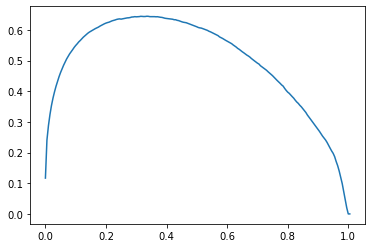

In [28]:
plot_f1_against_thresholds(train[target_col], train['preds'])

In [29]:
# test['preds'] = (clf_lgb.predict(test) * 0.5 +clf_lgb_re.predict(test)*0.5)*0.5+ (clf_cb.predict(test) * 0.5 + clf_cb_re.predict(test)*0.5)*0.5

In [30]:
test_preds = []

for model in all_models:
    test_preds.append(model.predict(test))
    

5it [00:05,  1.09s/it]
5it [00:05,  1.05s/it]
5it [00:05,  1.07s/it]
5it [00:05,  1.18s/it]
5it [00:05,  1.09s/it]


In [31]:
pd.Series(test_preds[0]).describe()

count    89786.000000
mean         0.060982
std          0.163866
min          0.000003
25%          0.000018
50%          0.003383
75%          0.025572
max          0.999564
dtype: float64

In [32]:
pd.Series(all_models[0].oofs).describe()

count    209499.000000
mean          0.060961
std           0.165161
min           0.000001
25%           0.000016
50%           0.003262
75%           0.024920
max           0.999891
dtype: float64

In [33]:
test_preds_avgd = np.mean(test_preds, axis=0)

In [34]:
test_preds_avgd.max()

0.9995335095640353

In [35]:
test['preds'] = test_preds_avgd

C:\Users\devni\AppData\Local\Temp\ipykernel_28840\3389789178.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  test['preds'] = test_preds_avgd


In [36]:
train['preds'].describe()

count    209499.000000
mean          0.060910
std           0.164536
min           0.000002
25%           0.000020
50%           0.003376
75%           0.025204
max           0.999900
Name: preds, dtype: float64

In [37]:
test['preds'].describe()

count    89786.000000
mean         0.060966
std          0.163965
min          0.000004
25%          0.000021
50%          0.003374
75%          0.025475
max          0.999534
Name: preds, dtype: float64

In [38]:
f1_score(train[target_col], train['preds'] > 0.32)

0.6441800469754726

In [39]:
ss['income_above_limit'] = (test['preds'].values > 0.32)*1
ss['income_above_limit'].value_counts(normalize=True)

0    0.937875
1    0.062125
Name: income_above_limit, dtype: float64

In [40]:
ss.to_csv(os.path.join(Config.OUTPUT_DIR, f'submission_{Config.VER}.csv'), index=False)

In [41]:
train[['ID', 'preds']].to_csv(os.path.join(Config.OUTPUT_DIR, f'train_preds_{Config.VER}.csv'), index=False)
test[['ID', 'preds']].to_csv(os.path.join(Config.OUTPUT_DIR, f'test_preds_{Config.VER}.csv'), index=False)